# ¿Qué sabíamos realmente al congelar el holdout?

## Pregunta y utilidad
La auditoría parcial1nov requiere equivalencia completa entre adjudicados. Ahora un contrato ejecutable distingue esa semántica de enlaces positivos y comprueba fecha efectiva **y disponibilidad** frente al corte. El resultado es elegibilidad de metadatos, no autenticación ni garantía de independencia de un pipeline ML. Se conserva el auditor y sus derivaciones.

Comando único: `bash run_snapshot_gate.sh`. Datos sintéticos;144 casos de conformidad y6 políticas,864 filas CSV. Umbrales previos en config_snapshot1102.json:0 discrepancias con oráculo independiente y72 pares de offsets invariantes. No estimamos prevalencia de fugas ni AUC.

In [1]:
import json,csv
from pathlib import Path
from dataclasses import replace
from IPython.display import display,Image
from src.snapshot_gate import AdjudicationSnapshot,prospective_audit,verify_manifest
from src.partial_audit import partial_audit
from src.splitter import Record
cfg=json.loads(Path('config_snapshot1102.json').read_text())
print(cfg['hypothesis'],'\nUmbral:',cfg['threshold'])

Prospective metadata gate agrees exactly with an independent integer policy oracle, blocks future availability and insufficient semantics, and preserves eligible partial auditor outputs 
Umbral: 144/144 oracle agreement,0 false admissions/rejections,72/72 UTC-offset manifest invariance; inherited5508 bound-oracle configs still pass


# De cotas condicionales a elegibilidad temporal y semántica

## Original y limitación

El1nov, partial_audit calcula extremos $[L,H]$ de filas expuestas sobre completaciones consistentes con equivalencia completa entre adjudicados. Para clases mixtas conocidas M, clases puras train ordenadas por tamaño $a_i$, puras test $b_j$ y desconocidos $u_{train},u_{test}$:

$$L=\sum_{m\in M}|m|,\qquad H=L+u+\sum_{i=1}^{\min(p,u_{test})}a_i+\sum_{j=1}^{\min(q,u_{train})}b_j.$$

La derivación y alcanzabilidad se conservan en derivacion1101.md y sus5508 configuraciones exhaustivas. No se modifica esa fórmula. La limitación es operacional/epistémica: la API no podía saber si el llamador suministraba enlaces positivos incompletos como equivalencia, ni cuándo estaban disponibles. Evaluar correctamente una fórmula con entradas semánticamente inválidas no valida el resultado.

## Notación, dominio y regla propuesta

Snapshot S declara filas adjudicadas K⊆V, fuente s, versión v, semántica q, fecha efectiva e y fecha de disponibilidad a. El corte congelado es c. Las fechas son instantes ISO8601 con zona; se normalizan UTC antes de comparar, no cadenas de offsets distintos. q debe declarar equivalencia completa **entre el subconjunto adjudicado**, incluidas diferencias entre clases. Enlaces positivos no acreditan esas diferencias.

$$G(S,c)=1\{v=1\}\,1\{s\ne\varnothing\}\,1\{q=\mathrm{equiv\_complete}\}\,1\{e\le c\}\,1\{a\le c\}.$$

Fuente vacía/solo espacios no es admisible. Fechas sin zona o inválidas, IDs fuera de universo, duplicados y asignación incompleta producen ValueError. Otras incompatibilidades devuelven blocked con motivos y **sin cotas**. Si G=1 se llama el auditor1nov y devuelve metadata-eligible: la interpretación depende aún de corrección de adjudicación. No convertirlo en validado/operacional.

## Derivación y propiedades

1. A partir del supuesto de información prospectiva, solo evidencia ya disponible a c puede usarse para construir/justificar la partición: a≤c. Saber hoy que una identidad era válida en e≤c no implica que se conociera entonces. Por eso e≤c solo es insuficiente.
2. La igualdad q=equivalencia completa es requisito para impedir fusiones entre clases adjudicadas diferentes en la derivación1nov; sin ese dato, su conjunto de completaciones puede ser demasiado pequeño. El gate no infiere semántica a partir de etiquetas singleton ni de cobertura.
3. Intersecar esas condiciones con esquema conocido/fuente declarada define G. Si G=1, se preservan EXACTAMENTE L/H del auditor1nov; si G=0, se abstiene en lugar de inventar un intervalo. Esta es disciplina conocida de contratos/point-in-time, no nueva teoría ML.
4. Con declaraciones honestas, la regla implica a≤c y e≤c por construcción. No prueba ausencia de fuga en features, etiquetas, selección de muestra, tuning o links observados usados antes del gate. El snapshot de identidades se supone estático y aplicable al caso histórico; no modela identidades que cambian de validez ni expiraciones.
5. El predicado event-time-only omite a≤c: con e=c y a=c+1µs admite información futura. Contrajemplo determinista; no resultado estadístico ni prevalencia empírica. Si fechas/fuente mienten, puede pasar: límite de confianza conservado explícitamente.

## Manifest e integridad

Sea P el payload que incluye snapshot, observed, asignación congelada y corte. Se ordenan IDs/identidades, se normalizan offsets y se serializa JSON con claves ordenadas/separadores fijos y ASCII. $h=\operatorname{SHA256}(P)$ vincula esos bytes canónicos. Orden distinto y mismo instante con otro offset producen mismo h; cambiar fuente, corte o asignación normalmente cambia h (tests concretos, no demostración de ausencia de colisiones). verify_manifest vuelve a calcular y compara el digest. No firma, no autenticidad, no historial inmutable: quien altera payload y recalcula hash conserva verificación. No afirmar cumplimiento completo W3C PROV; se usa como inspiración para procedencia explícita.

Unidades: e/a/c en instantes UTC, latencias ilustrativas en horas, L/H en filas, coste en ns/bytes; digest sin unidad. Tiempo de serialización/hash y auditoría O(n log n+L_id+B) por ordenación/clausuras y B bytes de payload, memoria O(n+L_id+B); no constante ni gratis. Registro CPU/hardware real en environment.json. Instalación e I/O excluidos de benchmarks. Con v1, fuente y semántica correctas y fechas elegibles se recupera exactamente1nov; no se alteran ecuaciones anteriores ni contratos compartidos.


In [2]:
rows=[Record('a',('person-a',)),Record('b',('person-b',))]
assignment={'a':'train','b':'test'}
snapshot=AdjudicationSnapshot(tuple(rows),'synthetic-review',1,'complete-equivalence-on-subset',cfg['cutoff'],cfg['cutoff'])
accepted=prospective_audit(rows,assignment,snapshot,cfg['cutoff'])
late=prospective_audit(rows,assignment,replace(snapshot,available_at='2026-11-02T12:00:00.000001Z'),cfg['cutoff'])
positive=prospective_audit(rows,assignment,replace(snapshot,semantics='positive-links-only'),cfg['cutoff'])
print('Elegible:',accepted.status,accepted.audit)
print('Tardío:',late.status,late.reasons,late.audit)
print('Solo positivos:',positive.status,positive.reasons,positive.audit)
assert accepted.audit==partial_audit(rows,rows,assignment)
assert late.audit is None and positive.audit is None

Elegible: metadata-eligible PartialAudit(rows=2, adjudicated_rows=2, unknown_rows=0, declared_cuts=0, lower_exposed_rows=0, upper_exposed_rows=0, decision='conditional-zero')
Tardío: blocked ('unavailable-at-cutoff',) None
Solo positivos: blocked ('insufficient-semantics',) None


## Diseño y baselines justos
Se enumeran2 semánticas×2 esquemas×2 fuentes×3 fechas efectivas×3 fechas de disponibilidad×2 offsets=144 casos. Todas las políticas reciben el mismo snapshot y corte, sin datos predictivos. Oráculo independiente usa los offsets enteros del diseño, no el parser de fechas.

Baselines: referencia as-of conocida (mismas condiciones, implementación declarativa independiente), abstenerse siempre (sin falsos admitidos, descarta elegibles), ablation event-time-only y semantics-only. La llamada1101 sin respetar sus precondiciones se incluye **como mal uso deliberado**, no competidor científico débil para proclamar superioridad. El gate debe empatar referencia as-of, no inventar un método más preciso. La matriz adversarial no es muestra de producción.

In [3]:
raw=list(csv.DictReader(Path('results/snapshot1102/raw.csv').open()))
s=json.loads(Path('results/snapshot1102/summary.json').read_text())
assert len(raw)==864
for policy,v in s.items():print(policy,v)
assert s['prospective_gate']==s['asof_reference']
assert s['prospective_gate']['false_admit']==s['prospective_gate']['false_reject']==0
assert s['event_time_only']['false_admit']==4
print('El gate empata disciplina as-of; no mejora matemática respecto a ella.')

ungated1101_misuse {'admitted': 144, 'false_admit': 136, 'false_reject': 0, 'cases': 144}
semantics_only {'admitted': 18, 'false_admit': 10, 'false_reject': 0, 'cases': 144}
event_time_only {'admitted': 12, 'false_admit': 4, 'false_reject': 0, 'cases': 144}
asof_reference {'admitted': 8, 'false_admit': 0, 'false_reject': 0, 'cases': 144}
prospective_gate {'admitted': 8, 'false_admit': 0, 'false_reject': 0, 'cases': 144}
abstain_all {'admitted': 0, 'false_admit': 0, 'false_reject': 8, 'cases': 144}
El gate empata disciplina as-of; no mejora matemática respecto a ella.


## Mecánica de admisión y coste de abstenerse
La figura contabiliza solo decisiones de política: las barras no representan fuga predictiva real. Cada política enfrenta144 casos,8 elegibles según el contrato. El mal uso1101 se excluye del gráfico para no dominar la escala; sus144 admisiones y136 inadmisibles quedan en tabla/CSV.

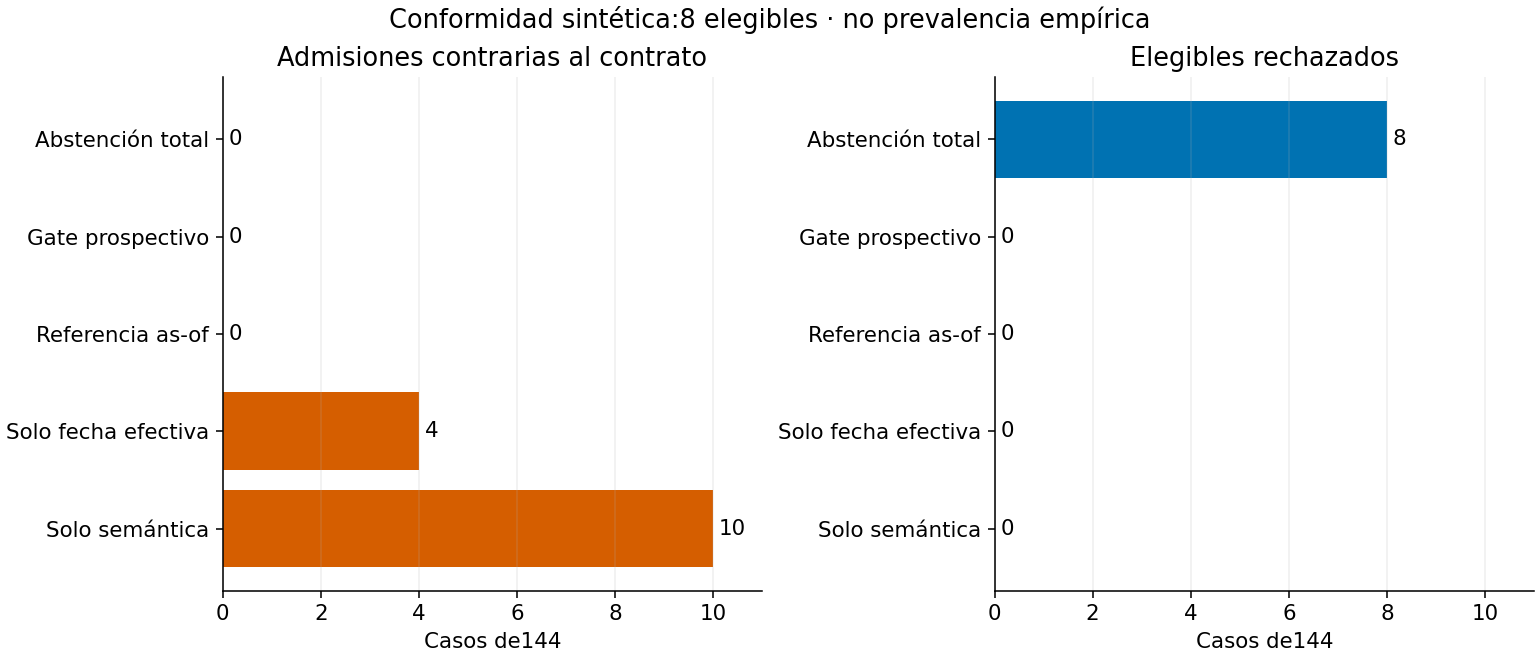

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
policies=['semantics_only','event_time_only','asof_reference','prospective_gate','abstain_all']
labels=['Solo semántica','Solo fecha efectiva','Referencia as-of','Gate prospectivo','Abstención total']
fig,axs=plt.subplots(1,2,figsize=(11,4.7),layout='constrained')
for ax,metric,title,color in [(axs[0],'false_admit','Admisiones contrarias al contrato','#D55E00'),(axs[1],'false_reject','Elegibles rechazados','#0072B2')]:
 vals=[s[p][metric] for p in policies]
 ax.barh(labels,vals,color=color)
 ax.bar_label(ax.containers[0],padding=3)
 ax.set(title=title,xlabel='Casos de144',xlim=(0,11));ax.grid(axis='x',alpha=.2)
fig.suptitle('Conformidad sintética:8 elegibles · no prevalencia empírica')
fig.savefig('results/snapshot1102/policy.png',dpi=140)
display(Image(filename='results/snapshot1102/policy.png'));plt.close(fig)

## Procedencia e integridad: lo que el hash no resuelve
Manifest conserva payload canónico, corte, asignación y digest. El verificador detecta modificación sin actualizar digest; no verifica verdad ni firma de fuente. La siguiente ablation cambia el payload y luego recalcula hash: pasa la verificación, como debe hacerlo un checksum sin autenticación. También se conserva un negativo: fuente/semántica/fechas falsas pero formalmente admisibles pueden producir cota0 con exposición real8.

In [5]:
import copy,hashlib
manifest=accepted.manifest
assert verify_manifest(manifest)
changed=copy.deepcopy(manifest);changed['payload']['source_id']='forged-source'
assert not verify_manifest(changed)
encoded=json.dumps(changed['payload'],sort_keys=True,separators=(',',':'),ensure_ascii=True,allow_nan=False).encode()
changed['input_sha256']=hashlib.sha256(encoded).hexdigest()
assert verify_manifest(changed)
print('Checksum original:',manifest['input_sha256'])
print('Hash recalculado acepta fuente falsa: no es autenticación.')
negative=json.loads(Path('results/snapshot1102/negative.json').read_text())
print('Negativo de confianza:',negative)
assert negative['claimed_upper']==0 and negative['actual_exposure']==8
manifests=json.loads(Path('results/snapshot1102/manifests.json').read_text())
assert all(manifests[i]['manifest']==manifests[i+1]['manifest'] for i in range(0,len(manifests),2))
print('72/72 pares de offsets equivalentes conservan payload y hash.')

Checksum original: 1805dd43cee304363987cc83e845453663491fbab8eb6a9bc62bb30e83462574
Hash recalculado acepta fuente falsa: no es autenticación.
Negativo de confianza: {'gate_status': 'metadata-eligible', 'claimed_upper': 0, 'actual_exposure': 8, 'scope': 'outside trust assumptions: declarations and dates can lie; digest does not authenticate'}
72/72 pares de offsets equivalentes conservan payload y hash.


## Escala del contrato completo
Tiempo y pico de memoria incluyen validación, serialización/hash y auditor parcial. Tres repeticiones por tamaño, sin inferencia poblacional ni coste monetario. No son resultados del DP de balance, no se modifican sus guardias. Instalación, carga, escritura y render notebook se excluyen. El manifiesto añade coste; no es una mejora de velocidad.

Mediana cómputo gate+auditor (ms) {28: 3.067537, 280: 29.110122, 2800: 212.015547, 28000: 2744.624129}
Mediana pico tracemalloc (MiB) {28: 0.027700424194335938, 280: 0.2686176300048828, 2800: 3.0950965881347656, 28000: 29.592693328857422}


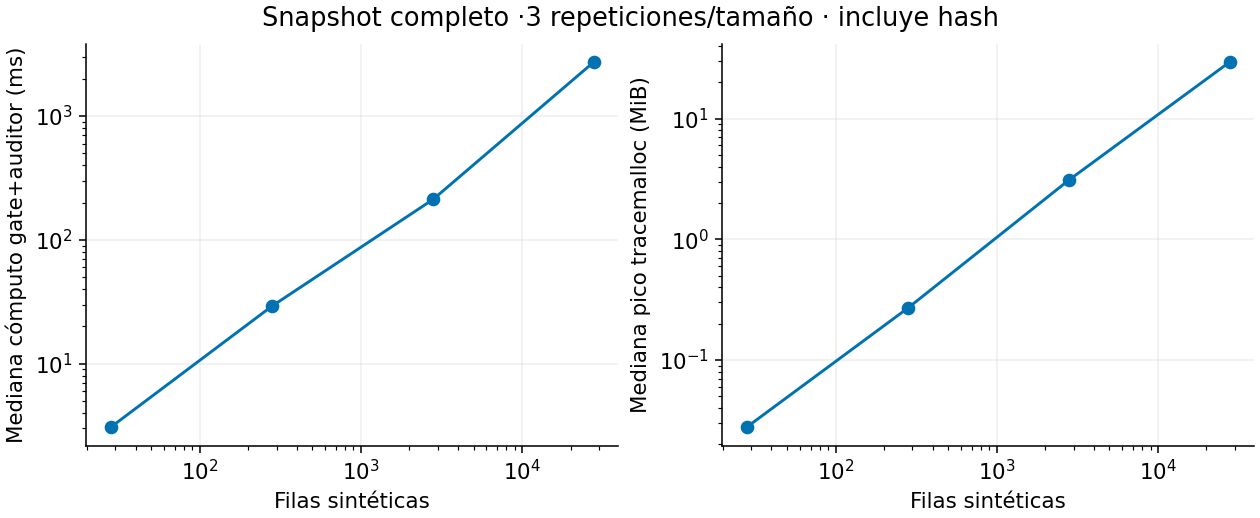

In [6]:
import statistics
scale=json.loads(Path('results/snapshot1102/scale.json').read_text())
sizes=sorted({r['rows'] for r in scale})
fig,axs=plt.subplots(1,2,figsize=(9,3.7),layout='constrained')
for ax,field,factor,label in [(axs[0],'elapsed_ns',1e6,'Mediana cómputo gate+auditor (ms)'),(axs[1],'peak_bytes',1024**2,'Mediana pico tracemalloc (MiB)')]:
 values=[statistics.median(r[field]/factor for r in scale if r['rows']==n) for n in sizes]
 print(label,dict(zip(sizes,values)))
 ax.loglog(sizes,values,marker='o',color='#0072B2');ax.set(xlabel='Filas sintéticas',ylabel=label);ax.grid(alpha=.2)
fig.suptitle('Snapshot completo ·3 repeticiones/tamaño · incluye hash')
fig.savefig('results/snapshot1102/cost.png',dpi=140)
display(Image(filename='results/snapshot1102/cost.png'));plt.close(fig)

## Qué sabemos y qué podemos hacer ahora
Ahora podemos impedir llamadas prospectivas con semántica/fechas declaradas inadmisibles y conservar un manifiesto de entrada reproducible. Antes la misma fórmula podía ejecutarse sin esos metadatos. La referencia as-of empata al gate: aporte local de contrato y trazabilidad, no innovación algorítmica acreditada. Las10 admisiones inadmisibles de semantics-only y4 de event-time-only explicitan por qué disponibilidad importa.

No sabemos si fuente/fechas son honestas, si identidades cambian ni si features/labels/tuning usan futuro. Continuar con fuente adjudicada auditable y política temporal de observados; ajustar si solo hay enlaces positivos; cerrar cualquier claim de autenticación o ausencia total de fuga con este gate. El pilarML continúa porque deja un supuesto bloqueante del programa en forma ejecutable; rotar ahora dejaría esa brecha abierta. Prototipo experimental, no validación empírica ni operación.

Fuentes primarias abiertas2nov2026: W3C PROV-DM2013 (procedencia conceptual, no conformidad completa); Python datetime aware; Feast point-in-time joins (principio conocido, no implementación Feast ni garantía de availability); Kapoor/Narayanan2023 PMC; Binette/Steorts arXiv2008.04443 (resumen/metadatos). Matriz prior_art1102.md/BibTeX. Ejecución real IPython secuencial en proceso, no kernel aislado Jupyter ni frontend completo.